In [4]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)

# Support running from either the repository root or notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

TABLES_DIR = ROOT / "results" / "tables" / "member2"

MODEL_NAMES = {
    "logistic_tuned": "Logistic Regression",
    "random_forest_tuned": "Random Forest",
}

In [5]:
results = {}

for model_name in MODEL_NAMES:
    path = TABLES_DIR / f"{model_name}_metrics.json"

    with open(path, encoding="utf-8") as f:
        results[model_name] = json.load(f)

rows = []

for model_name, result in results.items():
    probability = result["validation_metrics"]["probability_metrics"]
    threshold = result["validation_metrics"]["threshold_metrics"]

    rows.append({
        "Model": MODEL_NAMES[model_name],
        "ROC-AUC": probability["roc_auc"],
        "PR-AUC (AP)": probability["pr_auc_average_precision"],
        "Brier Score": probability["brier_score"],
        "Precision": threshold["precision"],
        "Recall": threshold["recall"],
        "F1-score": threshold["f1"],
    })

comparison_df = pd.DataFrame(rows).set_index("Model")

display(comparison_df.round(4))

,ROC-AUC,PR-AUC (AP),Brier Score,Precision,Recall,F1-score
Model,,,,,,
Logistic Regression,0.8021,0.3136,0.1794,0.1823,0.6682,0.2865
Random Forest,0.8694,0.4013,0.0487,0.5887,0.1523,0.2419


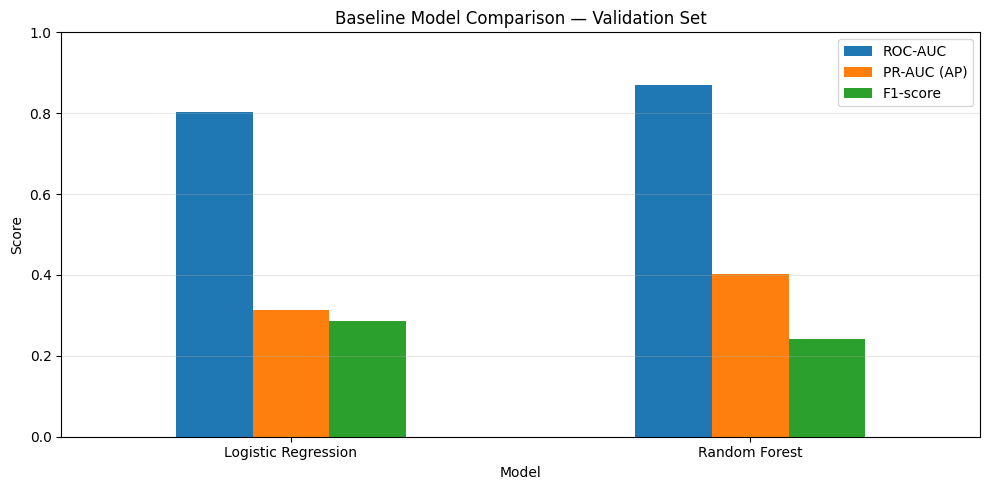

In [6]:
axes = comparison_df[
    ["ROC-AUC", "PR-AUC (AP)", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    ylim=(0, 1),
    title="Baseline Model Comparison — Validation Set",
)

axes.set_ylabel("Score")
axes.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
predictions = {}

for model_name in MODEL_NAMES:
    path = TABLES_DIR / f"{model_name}_validation_predictions.csv"
    predictions[model_name] = pd.read_csv(path)

    assert list(predictions[model_name].columns) == [
        "sample_id", "y_true", "y_pred_proba", "model_name", "split"
    ]
    assert len(predictions[model_name]) == 22500
    assert predictions[model_name]["split"].eq("validation").all()

# Both models must use exactly the same validation observations.
lr = predictions["logistic_tuned"]
rf = predictions["random_forest_tuned"]

np.testing.assert_array_equal(lr["sample_id"], rf["sample_id"])
np.testing.assert_array_equal(lr["y_true"], rf["y_true"])

print("Validation predictions loaded and aligned successfully.")

Validation predictions loaded and aligned successfully.


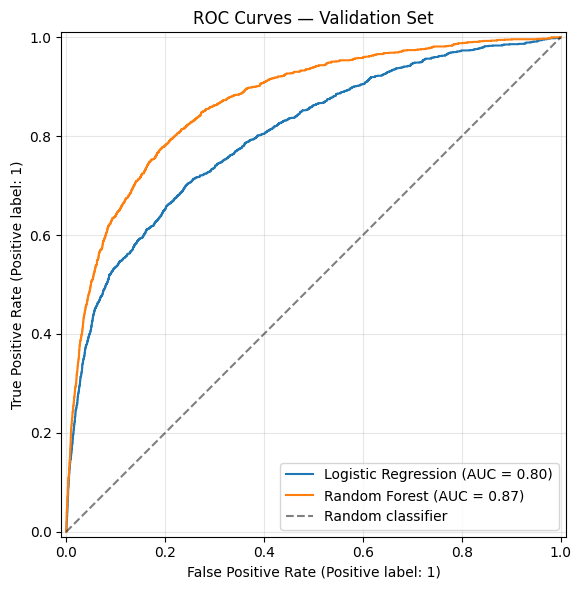

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, df in predictions.items():
    RocCurveDisplay.from_predictions(
        df["y_true"],
        df["y_pred_proba"],
        name=MODEL_NAMES[model_name],
        ax=ax,
    )

ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random classifier")
ax.set_title("ROC Curves — Validation Set")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

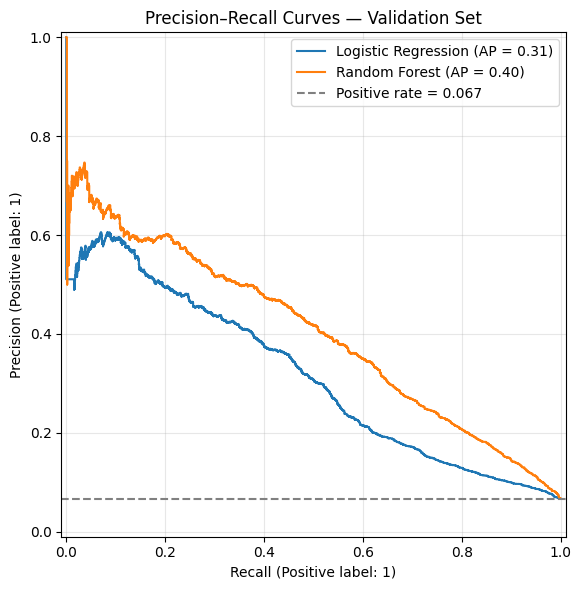

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, df in predictions.items():
    PrecisionRecallDisplay.from_predictions(
        df["y_true"],
        df["y_pred_proba"],
        name=MODEL_NAMES[model_name],
        ax=ax,
    )

positive_rate = lr["y_true"].mean()
ax.axhline(
    positive_rate,
    color="gray",
    linestyle="--",
    label=f"Positive rate = {positive_rate:.3f}",
)

ax.set_title("Precision–Recall Curves — Validation Set")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

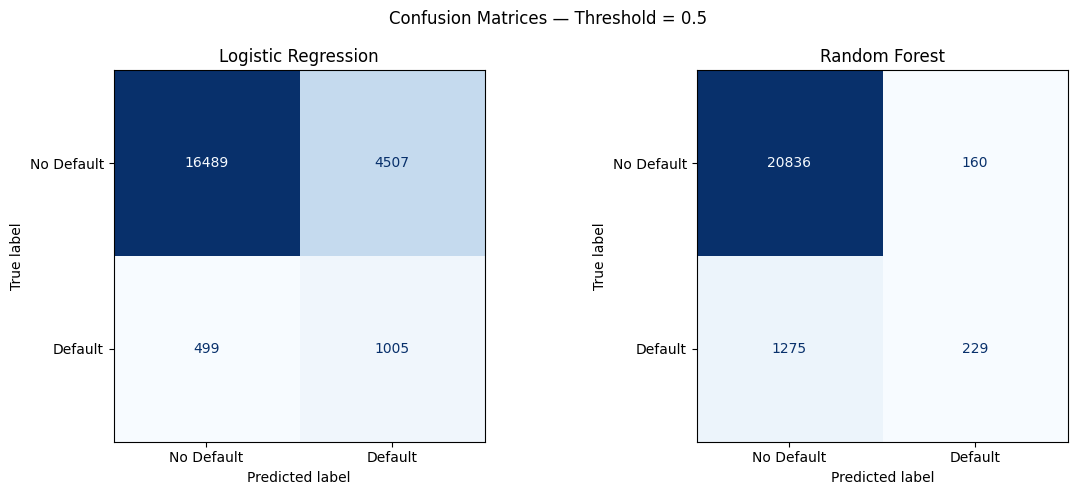

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, df) in zip(axes, predictions.items()):
    y_pred = (df["y_pred_proba"] >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        df["y_true"],
        y_pred,
        labels=[0, 1],
        display_labels=["No Default", "Default"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(MODEL_NAMES[model_name])

fig.suptitle("Confusion Matrices — Threshold = 0.5")
plt.tight_layout()
plt.show()